# Explore sketch- and gene-based quantification in metagenomes

The pancoding core project uses three different types of quantification:

* k-mer based coverage curves that fit to weighted_bp/intersect_bp from sketch intersection (species x metagenome) results;
* Gaussian mixture model peak finding in sketch intersection results;
* Mapping reads to (putative) species-specific gene sequences;

The mapping appoach is implemented in `2026-pancoding-core/scripts/summarize-mapping-depth-to-csv.py` and the k-mer-based approaches are both implemented in `2026-pancoding-core/scripts/isect-estimate-species-abundances.py`.

This notebook explores these approaches using results generated from the pancoding core scripts applied to simulated data (see the Snakefile).

## Using different references

The main motivation for this simulation approach was to evaluate what happened when the reference sequence being used for the quantification was divergent. So, we generate two collections of sequences, 'A' and 'B'. 'B' is ~4% divergent from 'A'. All of the reads are generated from 'A', and then some of the graphs below explore what happens when 'B' is used as the reference for quantification using those reads.

## Issues for CTB to consider - 

* are we doing references right for mapping?? Yes I think so

In [1]:
import polars as pl
import matplotlib.pyplot as plt

## for converting between reg coverage and k-mer coverage

per [link](https://bioinformatics.stackexchange.com/questions/2152/formula-for-k-mer-coverage)  and [link](https://www.biostars.org/p/221672/),

$C_𝑘 = { C (R - K + 1) \over R }$

so

$C = { C_k R \over (R- K + 1) } $

In [2]:
# base coverage:
def base_cov(kmer_cov, *, k, r):
    return kmer_cov * r / (r - k + 1)

## Saturation curves when using different references

Q: What do the k-mer coverage curves look like when the "wrong" (divergent) reference is used?

A: curve details are different but curve shape and abundance estimation is same.

In [3]:
# read k-mer collector's curve info
kmer_df = pl.read_csv('pure/reads.isect.kmer_stats.csv')

Text(0.5, 1.0, 'Coverage saturation curves when using good & divergent refs')

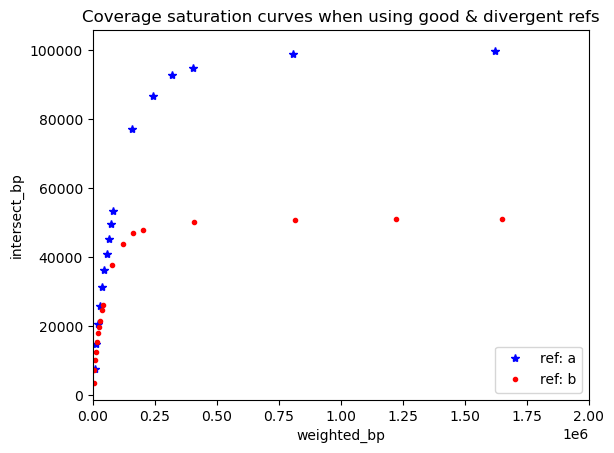

In [4]:
xx_df = kmer_df.filter(pl.col('species') == 'a')
yy_df = kmer_df.filter(pl.col('species') == 'b')
plt.plot(xx_df['weighted_bp'], xx_df['intersect_bp'], 'b*', label='ref: a')
plt.plot(yy_df['weighted_bp'], yy_df['intersect_bp'], 'r.', label='ref: b')

plt.xlim(0, 2e6)
plt.xlabel('weighted_bp')
plt.ylabel('intersect_bp')
plt.legend(loc='lower right')
plt.title('Coverage saturation curves when using good & divergent refs')

## Load combined coverage estimates

Q: how do coverage estimates vary with the combined k-mer estimates (cov curve and gmm approaches) when using the wrong reference?

A: the estimates are pretty similar; the reference doesn't seem to matter as long as it's reasonably close.

In [5]:
abund_df = (
    pl.read_csv('pure/reads.isect.abund.csv')
    .with_columns(
        cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32)
    )
)
abund_df['method'].unique()

method
str
"""covcurve_round1"""
"""gmm"""
"""covcurve_round2"""
"""composite"""
"""composite_k"""


## Compare k-mer abundance estimates vs different references for composite k-mer estimates

Q: How good is the composite k-mer abundance estimate (low coverage via coverage curve, high coverage via gaussian mixture model)?

A: systematically low, but still pretty darned good.

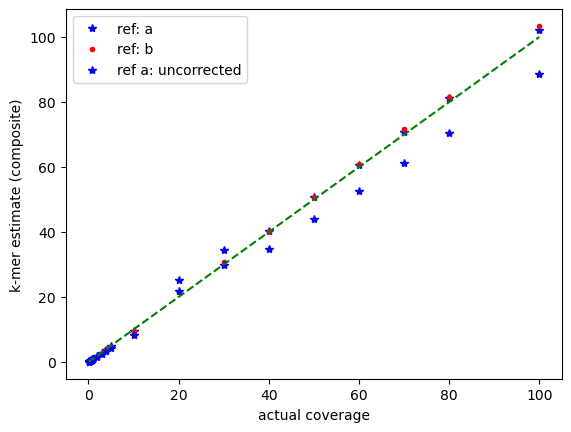

In [6]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite'))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite'))

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label='ref: a')
plt.plot(bb_df['cov'], bb_df['abund'], 'r.', label='ref: b')

uncorrected_aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite_k'))
plt.plot(aa_df['cov'], uncorrected_aa_df['abund'], 'b*', label='ref a: uncorrected')

plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer estimate (composite)')
plt.legend(loc='upper left')

## Compare k-mer abundance estimates vs different references for covcurve specifically

Q: How good are the coverage curve-based estimates?

A: systematically low, but still pretty darned good.

(Note that for _real_ data we have low-abundance strains that make an appearance, so this is systematically way too low on real data at high coverage, which is why we went with GMMs for > 10x.)

Text(0.5, 1.0, 'coverage curve-based k-mer estimates only')

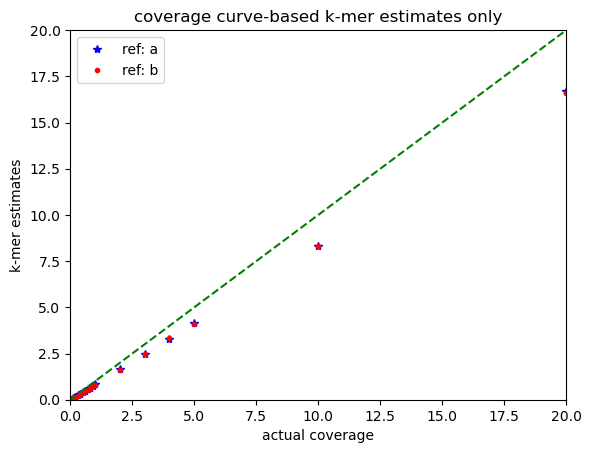

In [7]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'covcurve_round2'))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'covcurve_round2'))

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label='ref: a')
plt.plot(bb_df['cov'], bb_df['abund'], 'r.', label='ref: b')
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.plot([0, 100], [0, 100], 'g--')

plt.xlabel('actual coverage')
plt.ylabel('k-mer estimates')
plt.legend(loc='upper left')
plt.title('coverage curve-based k-mer estimates only')

## Load in the mapping abundances for both references

Mapping-based abundance is calculated here against all genes; reads are only from genome A, but mapped to genome A and B.

In [8]:
mapping_a_df = pl.read_csv('pure/mapping.a.csv').with_columns(
    species=pl.lit("a"),
    cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32),
)
mapping_b_df = pl.read_csv('pure/mapping.b.csv').with_columns(
    species=pl.lit("b"),
    cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32),
)

In [9]:
mapping_a_df

metag,gene,len,hits,breadth,depth_all,depth_cov,species,cov
str,str,i64,i64,f64,f64,f64,str,f32
"""R-0.1""","""A_72""",925,100,0.108108,0.108108,1.0,"""a""",0.1
"""R-0.1""","""A_97""",925,0,0.0,0.0,NaN,"""a""",0.1
"""R-0.1""","""A_63""",925,0,0.0,0.0,NaN,"""a""",0.1
"""R-0.1""","""A_86""",925,100,0.108108,0.108108,1.0,"""a""",0.1
"""R-0.1""","""A_93""",925,200,0.216216,0.216216,1.0,"""a""",0.1
…,…,…,…,…,…,…,…,…
"""R-100""","""A_59""",925,924,0.998919,98.135135,98.241342,"""a""",100.0
"""R-100""","""A_51""",925,924,0.998919,101.435676,101.545455,"""a""",100.0
"""R-100""","""A_79""",925,924,0.998919,105.525405,105.63961,"""a""",100.0


## How good is mapping based coverage?

Q: How well does mapping-based coverage estimate true coverage?

A: pretty darned well, but is always an overestimate!?

Text(0, 0.5, 'mapping coverage')

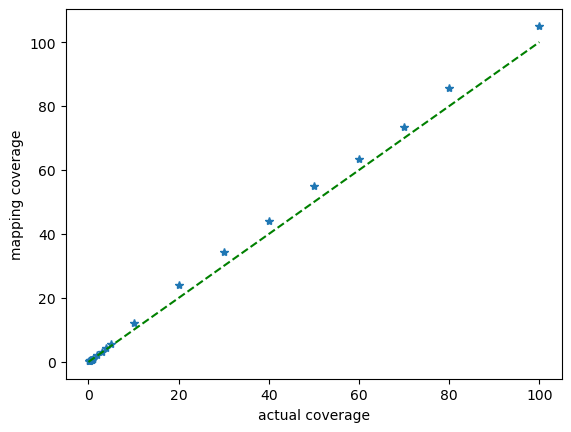

In [10]:
gene_df = (
    mapping_a_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all', 'cov'])
)
plt.plot(gene_df['cov'], gene_df['depth_all'], '*')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('mapping coverage')

## Combine k-mer estimation and mapping estimation into common data frame

Now let's compare mapping and k-mer based estimates...

In [11]:

aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite'))

gene_a_df = (
    mapping_a_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all'])
)
combo_a_df = gene_df.join(aa_df, on=['metag', 'species'], how='inner')
combo_a_df

metag,species,depth_all,cov,abund,method,cov_right
str,str,f64,f32,f64,str,f32
"""R-70""","""a""",73.473514,70.0,70.78449,"""composite""",70.0
"""R-0.5""","""a""",0.540541,0.5,0.458658,"""composite""",0.5
"""R-40""","""a""",44.078919,40.0,40.240715,"""composite""",40.0
"""R-5""","""a""",5.458378,5.0,4.796895,"""composite""",5.0
"""R-30""","""a""",34.423784,30.0,34.494677,"""composite""",30.0
…,…,…,…,…,…,…
"""R-100""","""a""",105.067027,100.0,102.084655,"""composite""",100.0
"""R-0.6""","""a""",0.648649,0.6,0.559657,"""composite""",0.6
"""R-2""","""a""",2.014054,2.0,1.905925,"""composite""",2.0


## Plot k-mer estimation and mapping abundance, with reads 'a' & genome 'a'

Text(0.5, 1.0, 'mapping vs k-mers with good ref genome')

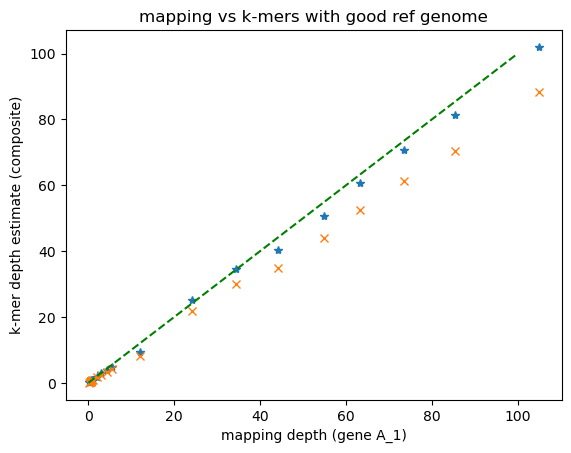

In [12]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method').is_in(['composite', 'composite_k'])))

gene_a_df = (
    mapping_a_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all'])
)
combo_a_df = gene_a_df.join(aa_df, on=['metag', 'species'], how='inner')

corrected_df = combo_a_df.filter(pl.col('method') == 'composite')
plt.plot(corrected_df['depth_all'], corrected_df['abund'], '*')
uncorrected_df = combo_a_df.filter(pl.col('method') == 'composite_k')
plt.plot(uncorrected_df['depth_all'], uncorrected_df['abund'], 'x')

plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('mapping depth (gene A_1)')
plt.ylabel('k-mer depth estimate (composite)')
plt.title('mapping vs k-mers with good ref genome')

Text(0.5, 1.0, 'mapping vs k-mers when using more divergent genome as a reference')

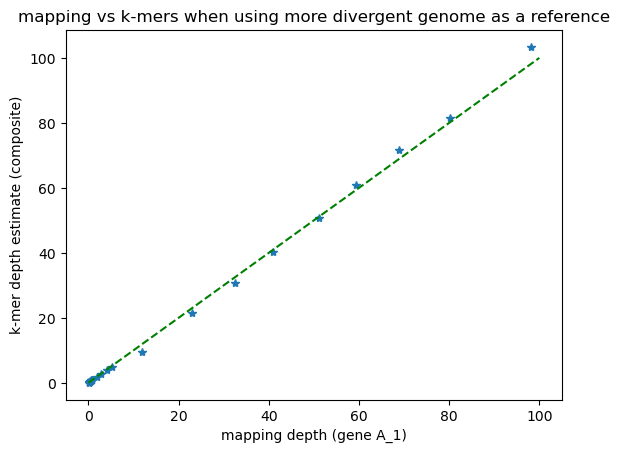

In [13]:
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite'))

gene_b_df = (
    mapping_b_df
    .filter(pl.col('gene') == "A_1")
    .select(['metag', 'species', 'depth_all'])
)
combo_b_df = gene_b_df.join(bb_df, on=['metag', 'species'], how='inner')

plt.plot(combo_b_df['depth_all'], combo_b_df['abund'], '*')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('mapping depth (gene A_1)')
plt.ylabel('k-mer depth estimate (composite)')
plt.title("mapping vs k-mers when using more divergent genome as a reference")

## Concluding thoughts

* k-mer estimates closely correspond to mapping abundance estimates for this simulated dataset
* mapping based estimates always seem to overestimate abundance a bit, for reasons I don't understand.
* divergent genomes don't seem to matter that much